In [2]:
# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

# Model selection & Cross-validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
# (Optional: uncomment if you have xgboost installed)
# from xgboost import XGBClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Model serialization
import joblib

# System & Settings
import warnings
warnings.filterwarnings('ignore')

# Visual style for plots
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
df=pd.read_csv("MP_Synthetics_50000_Rows.csv")
df.head()


,Customer_ID,Company_Name,Industry,Country,Company_Size,Account_Manager,Plan_Tier,Billing_Cycle,Monthly_Recurring_Revenue,Signup_Date,Last_Active_Date,Payment_Status,Active_Seats_Used,Total_Seats_Allowed,Support_Tickets_30d,Feature_Adoption_Rate,Churn_Risk_Score,Is_Churned
0,CUST-1001,Pulse Net 944,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,2025-03-12,2026-02-18,Active,3,8,5,44%,Low,0
1,CUST-1002,Pulse Logic 332,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,2023-09-29,2026-02-25,Active,13,24,3,58%,Low,0
2,CUST-1003,Secure Flow 975,DevTools,India,1-10,David Ross,Starter,Monthly,79,2025-03-16,2026-02-19,Active,6,8,5,70%,Low,0
3,CUST-1004,Quantum Scale 657,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,2024-03-05,2026-02-22,Active,34,39,2,90%,Low,0
4,CUST-1005,Quantum Sphere 308,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,2025-02-28,2026-02-22,Active,8,9,3,93%,Low,0


In [4]:
df.dtypes

Customer_ID                    str
Company_Name                   str
Industry                       str
Country                        str
Company_Size                   str
Account_Manager                str
Plan_Tier                      str
Billing_Cycle                  str
Monthly_Recurring_Revenue    int64
Signup_Date                    str
Last_Active_Date               str
Payment_Status                 str
Active_Seats_Used            int64
Total_Seats_Allowed          int64
Support_Tickets_30d          int64
Feature_Adoption_Rate          str
Churn_Risk_Score               str
Is_Churned                   int64
dtype: object

In [5]:
# Check missing values count and percentage per column
missing_data = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

missing_data.sort_values(by='Missing_Count', ascending=False)

,Missing_Count,Missing_Percentage (%)
Customer_ID,0,0.0
Company_Name,0,0.0
Industry,0,0.0
Country,0,0.0
Company_Size,0,0.0
Account_Manager,0,0.0
Plan_Tier,0,0.0
Billing_Cycle,0,0.0
Monthly_Recurring_Revenue,0,0.0
Signup_Date,0,0.0


--- Target Distribution (Is_Churned) ---


,Count,Percentage (%)
Is_Churned,,
0,49084,98.17
1,916,1.83


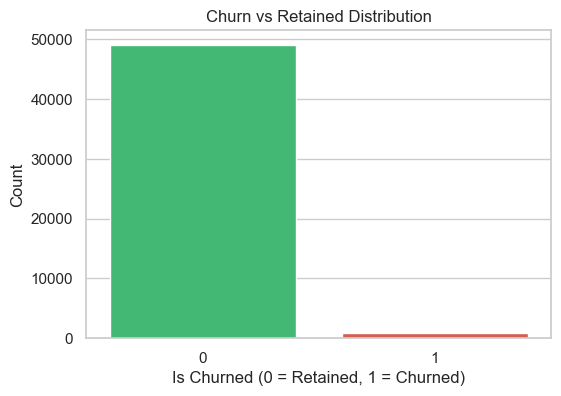

In [7]:
# 1. Target distribution counts and percentages
churn_counts = df['Is_Churned'].value_counts()
churn_percentage = df['Is_Churned'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Count': churn_counts,
    'Percentage (%)': churn_percentage.round(2)
})
print("--- Target Distribution (Is_Churned) ---")
display(summary_df)

# Quick visualization
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Is_Churned', palette=['#2ecc71', '#e74c3c'])
plt.title('Churn vs Retained Distribution')
plt.xlabel('Is Churned (0 = Retained, 1 = Churned)')
plt.ylabel('Count')
plt.show()

In [8]:
# Strip '%' sign and convert to float (0.0 to 100.0)
df['Feature_Adoption_Rate'] = df['Feature_Adoption_Rate'].astype(str).str.rstrip('%').astype(float)

# Verify the conversion
print("Feature_Adoption_Rate data type:", df['Feature_Adoption_Rate'].dtype)
df[['Feature_Adoption_Rate']].describe()

Feature_Adoption_Rate data type: float64


,Feature_Adoption_Rate
count,50000.000000
mean,69.786500
std,18.068043
min,30.000000
25%,55.000000
50%,70.000000
75%,85.000000
max,100.000000


In [9]:
# Convert to datetime
df['Signup_Date'] = pd.to_datetime(df['Signup_Date'])
df['Last_Active_Date'] = pd.to_datetime(df['Last_Active_Date'])

# Reference date (the most recent date observed in the dataset)
reference_date = df['Last_Active_Date'].max()

# 1. Account Tenure: Days since the customer originally signed up
df['Tenure_Days'] = (reference_date - df['Signup_Date']).dt.days

# 2. Days Inactive: Days since the customer was last seen active
df['Days_Inactive'] = (reference_date - df['Last_Active_Date']).dt.days

# Check summary of engineered date features
df[['Tenure_Days', 'Days_Inactive']].describe()

,Tenure_Days,Days_Inactive
count,50000.000000,50000.000000
mean,611.192080,8.255060
std,337.591367,14.838193
min,30.000000,0.000000
25%,318.000000,3.000000
50%,611.000000,7.000000
75%,902.000000,10.000000
max,1199.000000,179.000000


In [10]:
# Calculate seat utilization ratio (clipped at 1.0 in case active > total)
df['Seat_Utilization_Rate'] = (df['Active_Seats_Used'] / df['Total_Seats_Allowed']).clip(upper=1.0)

# Check statistics
df['Seat_Utilization_Rate'].describe()

count    50000.000000
mean         0.638654
std          0.180814
min          0.250000
25%          0.500000
50%          0.666667
75%          0.791667
max          0.998895
Name: Seat_Utilization_Rate, dtype: float64

In [11]:
# Drop identifiers and original date strings
drop_cols = ['Customer_ID', 'Company_Name', 'Signup_Date', 'Last_Active_Date']
df.drop(columns=drop_cols, inplace=True)

print(f"Remaining columns: {df.shape[1]}")
df.head()

Remaining columns: 17


,Industry,Country,Company_Size,Account_Manager,Plan_Tier,Billing_Cycle,Monthly_Recurring_Revenue,Payment_Status,Active_Seats_Used,Total_Seats_Allowed,Support_Tickets_30d,Feature_Adoption_Rate,Churn_Risk_Score,Is_Churned,Tenure_Days,Days_Inactive,Seat_Utilization_Rate
0,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,Active,3,8,5,44.0,Low,0,353,10,0.375000
1,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,Active,13,24,3,58.0,Low,0,883,3,0.541667
2,DevTools,India,1-10,David Ross,Starter,Monthly,79,Active,6,8,5,70.0,Low,0,349,9,0.750000
3,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,Active,34,39,2,90.0,Low,0,725,6,0.871795
4,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,Active,8,9,3,93.0,Low,0,365,6,0.888889


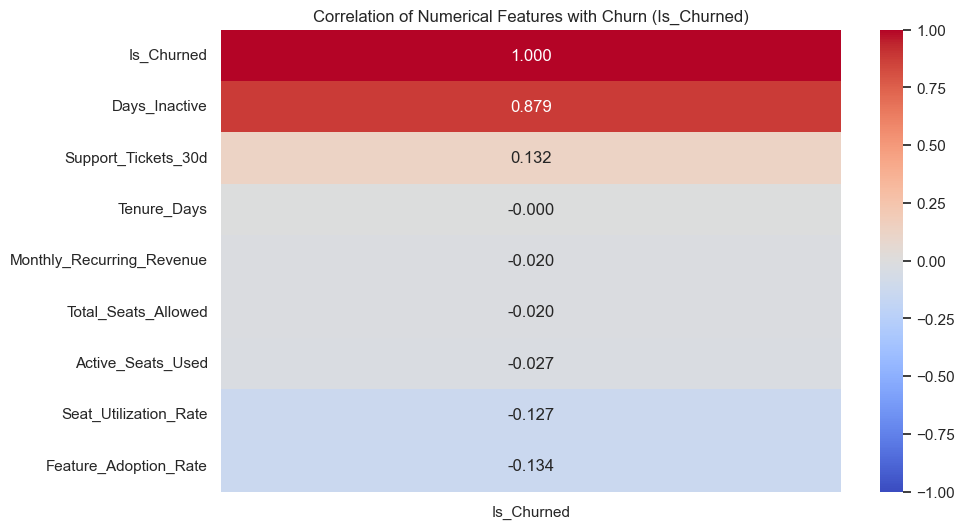

In [12]:
# Correlation of numeric features
plt.figure(figsize=(10, 6))
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = df[numeric_cols].corr()

# Plot heatmap focused on correlations with Is_Churned
sns.heatmap(corr_matrix[['Is_Churned']].sort_values(by='Is_Churned', ascending=False), 
            annot=True, cmap='coolwarm', fmt=".3f", vmin=-1, vmax=1)
plt.title('Correlation of Numerical Features with Churn (Is_Churned)')
plt.show()

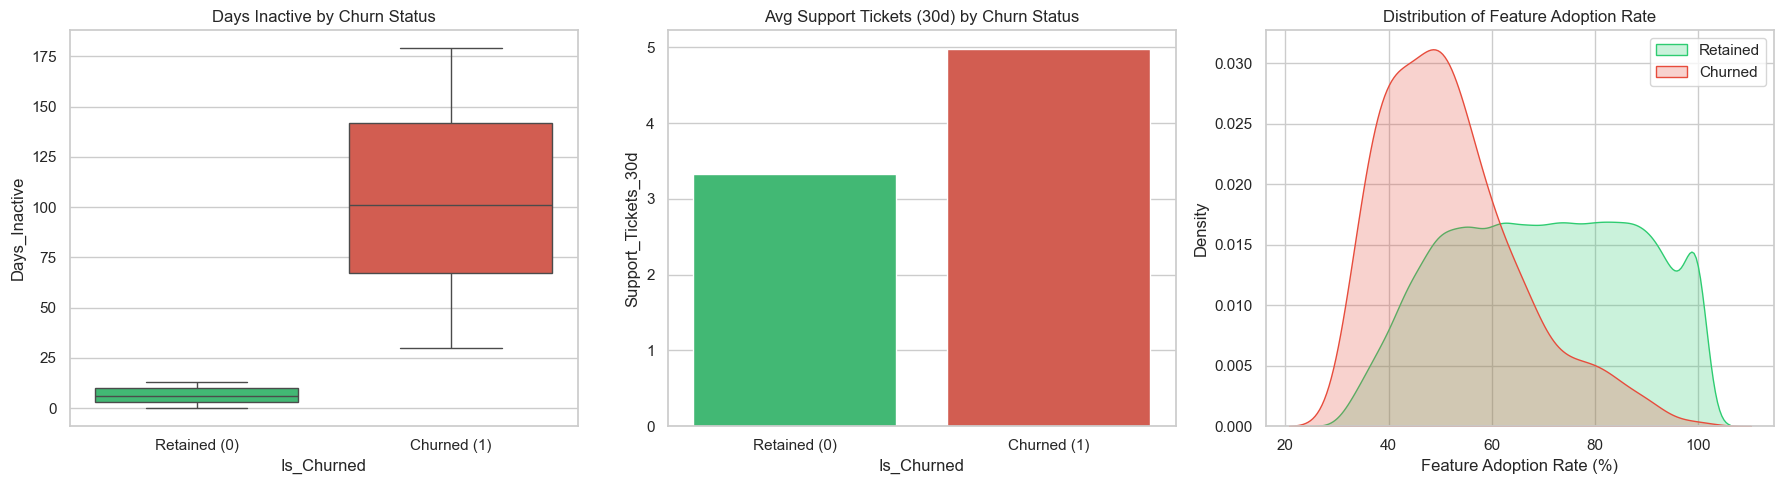

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Days Inactive vs Churn
sns.boxplot(ax=axes[0], data=df, x='Is_Churned', y='Days_Inactive', palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Days Inactive by Churn Status')
axes[0].set_xticklabels(['Retained (0)', 'Churned (1)'])

# 2. Support Tickets in Last 30 Days
sns.barplot(ax=axes[1], data=df, x='Is_Churned', y='Support_Tickets_30d', palette=['#2ecc71', '#e74c3c'], ci=None)
axes[1].set_title('Avg Support Tickets (30d) by Churn Status')
axes[1].set_xticklabels(['Retained (0)', 'Churned (1)'])

# 3. Feature Adoption Rate vs Churn
sns.kdeplot(ax=axes[2], data=df[df['Is_Churned']==0]['Feature_Adoption_Rate'], label='Retained', shade=True, color='#2ecc71')
sns.kdeplot(ax=axes[2], data=df[df['Is_Churned']==1]['Feature_Adoption_Rate'], label='Churned', shade=True, color='#e74c3c')
axes[2].set_title('Distribution of Feature Adoption Rate')
axes[2].set_xlabel('Feature Adoption Rate (%)')
axes[2].legend()

plt.tight_layout()
plt.show()

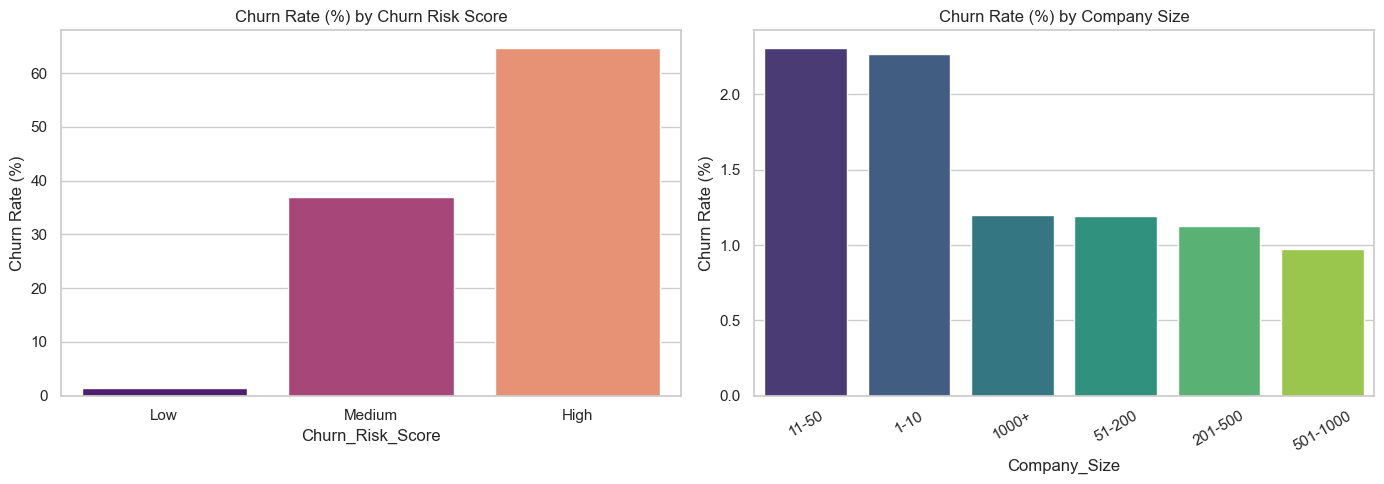

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Churn Risk Score Validation
risk_churn = df.groupby('Churn_Risk_Score')['Is_Churned'].mean().reset_index()
risk_churn['Churn_Rate_%'] = risk_churn['Is_Churned'] * 100
order = ['Low', 'Medium', 'High']
sns.barplot(ax=axes[0], data=risk_churn, x='Churn_Risk_Score', y='Churn_Rate_%', order=order, palette='magma')
axes[0].set_title('Churn Rate (%) by Churn Risk Score')
axes[0].set_ylabel('Churn Rate (%)')

# 2. Company Size vs Churn Rate
size_churn = df.groupby('Company_Size')['Is_Churned'].mean().reset_index()
size_churn['Churn_Rate_%'] = size_churn['Is_Churned'] * 100
sns.barplot(ax=axes[1], data=size_churn.sort_values(by='Churn_Rate_%', ascending=False), 
            x='Company_Size', y='Churn_Rate_%', palette='viridis')
axes[1].set_title('Churn Rate (%) by Company Size')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [15]:
# Define target (y) and feature matrix (X)
y = df['Is_Churned']
X = df.drop(columns=['Is_Churned'])

print(f"Features shape (X): {X.shape}")
print(f"Target shape (y):   {y.shape}")

Features shape (X): (50000, 16)
Target shape (y):   (50000,)


In [16]:
# Perform stratified 80-20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

# Verification: Check that the churn ratio is preserved in both sets
print("--- Split Summary ---")
print(f"X_train: {X_train.shape[0]} rows | X_test: {X_test.shape[0]} rows\n")

print(f"Train Churn Rate: {y_train.mean():.4f} ({y_train.sum()} churned)")
print(f"Test Churn Rate:  {y_test.mean():.4f} ({y_test.sum()} churned)")

--- Split Summary ---
X_train: 40000 rows | X_test: 10000 rows

Train Churn Rate: 0.0183 (733 churned)
Test Churn Rate:  0.0183 (183 churned)


In [17]:
# Identify numerical and categorical column names
numeric_features = [
    'Monthly_Recurring_Revenue',
    'Active_Seats_Used',
    'Total_Seats_Allowed',
    'Support_Tickets_30d',
    'Feature_Adoption_Rate',
    'Tenure_Days',
    'Days_Inactive',
    'Seat_Utilization_Rate'
]

categorical_features = [
    'Industry',
    'Country',
    'Company_Size',
    'Account_Manager',
    'Plan_Tier',
    'Billing_Cycle',
    'Payment_Status',
    'Churn_Risk_Score'
]

# Numeric pipeline: Impute missing (safety) -> Scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: Impute missing (safety) -> One-Hot Encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine both into a single preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessor configured successfully!")

Preprocessor configured successfully!


In [18]:
# Fit on X_train and transform a sample to verify
X_train_transformed = preprocessor.fit_transform(X_train)

print(f"Original X_train shape:    {X_train.shape}")
print(f"Transformed X_train shape: {X_train_transformed.shape}")

Original X_train shape:    (40000, 16)
Transformed X_train shape: (40000, 46)


In [19]:
# 1. Define candidate baseline models
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# 2. Stratified 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

print("Running Cross-Validation across candidate models...")
for model_name, model in models.items():
    # Build complete pipeline: Preprocessor + Model
    candidate_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Evaluate with ROC-AUC (standard metric for imbalanced classification)
    scores = cross_val_score(candidate_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    
    cv_results.append({
        'Model': model_name,
        'Mean ROC-AUC': scores.mean(),
        'Std ROC-AUC': scores.std()
    })
    print(f"✓ {model_name}: Mean ROC-AUC = {scores.mean():.4f} (± {scores.std():.4f})")

# Summary table
cv_summary_df = pd.DataFrame(cv_results).sort_values(by='Mean ROC-AUC', ascending=False)
display(cv_summary_df)

Running Cross-Validation across candidate models...
✓ Logistic Regression: Mean ROC-AUC = 1.0000 (± 0.0000)
✓ Random Forest: Mean ROC-AUC = 1.0000 (± 0.0000)
✓ Gradient Boosting: Mean ROC-AUC = 1.0000 (± 0.0000)


,Model,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,1.0,0.0
1,Random Forest,1.0,0.0
2,Gradient Boosting,1.0,0.0


In [20]:
# 1. Update numeric features list (removing Days_Inactive to prevent data leakage)
numeric_features = [
    'Monthly_Recurring_Revenue',
    'Active_Seats_Used',
    'Total_Seats_Allowed',
    'Support_Tickets_30d',
    'Feature_Adoption_Rate',
    'Tenure_Days',
    'Seat_Utilization_Rate'
]

categorical_features = [
    'Industry',
    'Country',
    'Company_Size',
    'Account_Manager',
    'Plan_Tier',
    'Billing_Cycle',
    'Payment_Status',
    'Churn_Risk_Score'
]

# 2. Re-create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_features)
    ]
)

# 3. Drop Days_Inactive from X_train and X_test
if 'Days_Inactive' in X_train.columns:
    X_train = X_train.drop(columns=['Days_Inactive'])
    X_test = X_test.drop(columns=['Days_Inactive'])

print("Leakage removed! Remaining features in X_train:", X_train.shape[1])

Leakage removed! Remaining features in X_train: 15


In [21]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# 2. Stratified 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

print("Running Cross-Validation across candidate models...")
for model_name, model in models.items():
    # Build complete pipeline: Preprocessor + Model
    candidate_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Evaluate with ROC-AUC (standard metric for imbalanced classification)
    scores = cross_val_score(candidate_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    
    cv_results.append({
        'Model': model_name,
        'Mean ROC-AUC': scores.mean(),
        'Std ROC-AUC': scores.std()
    })
    print(f"✓ {model_name}: Mean ROC-AUC = {scores.mean():.4f} (± {scores.std():.4f})")

# Summary table
cv_summary_df = pd.DataFrame(cv_results).sort_values(by='Mean ROC-AUC', ascending=False)
display(cv_summary_df)

Running Cross-Validation across candidate models...
✓ Logistic Regression: Mean ROC-AUC = 0.8646 (± 0.0099)
✓ Random Forest: Mean ROC-AUC = 0.8227 (± 0.0092)
✓ Gradient Boosting: Mean ROC-AUC = 0.8621 (± 0.0092)


,Model,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,0.864574,0.009927
2,Gradient Boosting,0.862137,0.009213
1,Random Forest,0.822738,0.009186



========================= Logistic Regression Test Evaluation =========================
              precision    recall  f1-score   support

Retained (0)       1.00      0.78      0.88      9817
 Churned (1)       0.06      0.79      0.12       183

    accuracy                           0.78     10000
   macro avg       0.53      0.79      0.50     10000
weighted avg       0.98      0.78      0.86     10000

Test ROC-AUC Score: 0.8567

========================= Random Forest Test Evaluation =========================
              precision    recall  f1-score   support

Retained (0)       0.98      0.99      0.99      9817
 Churned (1)       0.32      0.14      0.20       183

    accuracy                           0.98     10000
   macro avg       0.65      0.57      0.59     10000
weighted avg       0.97      0.98      0.97     10000

Test ROC-AUC Score: 0.8062

========================= Gradient Boosting Test Evaluation =========================
              precision    recall

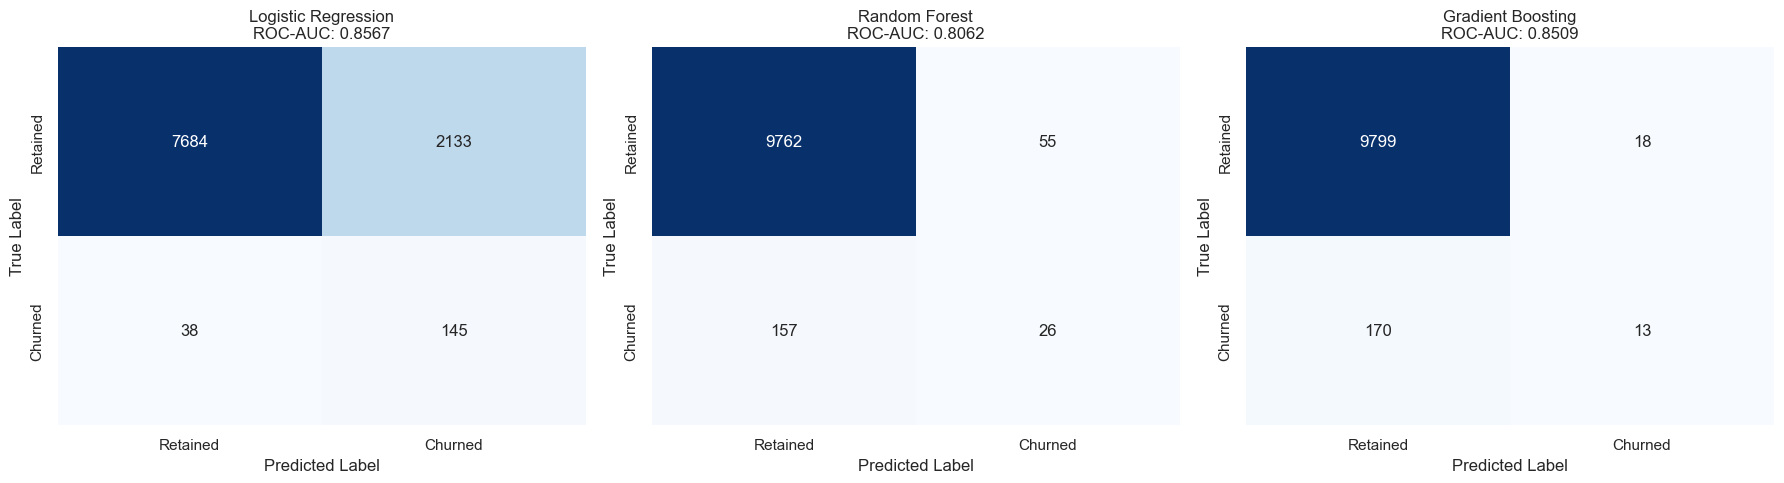

In [22]:
# Evaluate baseline models on unseen test set (X_test, y_test)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

test_eval_results = {}

for idx, (model_name, model) in enumerate(models.items()):
    # Create and fit full pipeline
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipe.fit(X_train, y_train)
    
    # Predictions and probabilities
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    test_eval_results[model_name] = {
        'pipeline': pipe,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'roc_auc': roc_auc_score(y_test, y_prob)
    }
    
    print(f"\n{'='*25} {model_name} Test Evaluation {'='*25}")
    print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))
    print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
    
    # Confusion matrix plot
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{model_name}\nROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")
    axes[idx].set_xticklabels(['Retained', 'Churned'])
    axes[idx].set_yticklabels(['Retained', 'Churned'])

plt.tight_layout()
plt.show()

In [23]:
# 1. Base pipeline with preprocessor and Logistic Regression
champion_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# 2. Define hyperparameter grid for tuning
param_grid = {
    'classifier__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
    'classifier__solver': ['lbfgs', 'liblinear']
}

# 3. Setup GridSearchCV with Stratified 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=champion_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Starting Hyperparameter Tuning with GridSearchCV...")
grid_search.fit(X_train, y_train)

# 4. Display best parameters and best CV ROC-AUC
print("\n" + "="*40)
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")
print("="*40)

# 5. Extract the best estimator as our final model
best_model = grid_search.best_estimator_

Starting Hyperparameter Tuning with GridSearchCV...
Fitting 5 folds for each of 14 candidates, totalling 70 fits

Best Parameters: {'classifier__C': 0.01, 'classifier__solver': 'lbfgs'}
Best Cross-Validation ROC-AUC: 0.8654


In [24]:
# Predictions on test data
y_pred_final = best_model.predict(X_test)
y_prob_final = best_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_prob_final)

print("--- Final Tuned Pipeline Test Metrics ---")
print(classification_report(y_test, y_pred_final, target_names=['Retained (0)', 'Churned (1)']))
print(f"Test ROC-AUC: {test_auc:.4f}")

--- Final Tuned Pipeline Test Metrics ---
              precision    recall  f1-score   support

Retained (0)       1.00      0.78      0.88      9817
 Churned (1)       0.06      0.79      0.12       183

    accuracy                           0.78     10000
   macro avg       0.53      0.79      0.50     10000
weighted avg       0.98      0.78      0.86     10000

Test ROC-AUC: 0.8566


In [25]:
# 1. Save the full pipeline (preprocessor + model together)
model_filename = "churn_pipeline.joblib"
joblib.dump(best_model, model_filename)
print(f"Model pipeline saved to: {model_filename}")

# 2. Save feature names and categorical unique values for Streamlit form inputs
app_metadata = {
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'categorical_options': {col: sorted(df[col].unique().tolist()) for col in categorical_features}
}
joblib.dump(app_metadata, "app_metadata.joblib")
print("App metadata saved to: app_metadata.joblib")

Model pipeline saved to: churn_pipeline.joblib
App metadata saved to: app_metadata.joblib


In [ ]:
s